# Titanic Survival — Beginner Classification Notebook

In this notebook we predict which passengers survived the Titanic disaster.
It is a classic **binary classification** problem: the target `Survived` is either 0 (did not survive) or 1 (survived).

We follow a simple, honest workflow:

1. Load the data
2. Explore it (EDA)
3. Clean it (fill missing values without leaking test information)
4. Build features
5. Compare models with cross-validation
6. Train the final model and write `submission.csv`
7. (Optional) Look at the mistakes the model makes

The code computes the dataset summaries and model scores shown below.

## How to run this notebook

- **Kaggle:** open the notebook in the Titanic competition, or click *Add Input* and add the **Titanic** competition data. The data appears in `/kaggle/input/titanic`.
- **Colab:** upload `train.csv` and `test.csv` next to the notebook, or into a folder called `data/`.
- **Locally:** keep `train.csv` and `test.csv` in the `data/` folder next to the notebook.

Then use **Runtime → Run all** (Colab) or **Cell → Run All** (Jupyter / Kaggle). A normal CPU is enough; no GPU and no internet download are needed.

The notebook writes `submission.csv` into the current working directory and also saves a copy in the local project folder when it exists.

### Library versions

The cell below prints the versions used for the executed results saved in this notebook. A rerun on another machine, or on Kaggle's default environment, can print different versions and different model-comparison results.

In [1]:
import sys

import matplotlib
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost

print("Python", sys.version.split()[0])
print("pandas", pd.__version__)
print("numpy", np.__version__)
print("matplotlib", matplotlib.__version__)
print("seaborn", sns.__version__)
print("scikit-learn", sklearn.__version__)
print("xgboost", xgboost.__version__)


Python 3.13.5
pandas 3.0.6
numpy 2.5.5
matplotlib 3.11.2
seaborn 0.13.2
scikit-learn 1.9.1
xgboost 3.4.1


## A. Setup

We import the libraries and fix the random seed. A fixed seed (`SEED`) makes the results repeatable: running the notebook again gives the same numbers.

In [1]:
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, confusion_matrix)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# XGBoost is optional: the notebook still works without it.
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")
%matplotlib inline

print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__)
print("XGBoost available:", HAS_XGB)
print("SEED =", SEED)

pandas 3.0.6 | numpy 2.5.5 | seaborn 0.13.2
XGBoost available: True
SEED = 42


### Find the data folder

The helper below checks a few common locations (Kaggle, this local project, a `data/` folder, the current folder, and its parent folder) and uses the first one that contains both `train.csv` and `test.csv`.

In [2]:
CANDIDATE_DIRS = [
    Path("/kaggle/input/titanic"),
    Path("/workspace/kaggle/titanic/data"),
    Path("data"),
    Path("."),
    Path(".."),
]


def find_data_dir(candidates=CANDIDATE_DIRS):
    # Return the first folder that contains both train.csv and test.csv.
    for folder in candidates:
        if (folder / "train.csv").is_file() and (folder / "test.csv").is_file():
            return folder
    raise FileNotFoundError(
        "Could not find train.csv and test.csv. Checked: "
        + ", ".join(str(c) for c in candidates)
    )


DATA_DIR = find_data_dir()
print("Using data folder:", DATA_DIR.resolve())

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

TARGET = "Survived"
ID_COL = "PassengerId"

print("train shape:", train.shape)
print("test shape: ", test.shape)

Using data folder: /workspace/kaggle/titanic/data
train shape: (891, 12)
test shape:  (418, 11)


### Column types and first rows

`train` has the target column `Survived`; `test` does not (Kaggle keeps those labels hidden).

In [3]:
print("Column dtypes (train):")
print(train.dtypes)

Column dtypes (train):
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object


In [4]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


### Missing values

The table counts empty cells per column in each file. Columns with many missing values need a plan in the cleaning step.

In [6]:
missing = pd.DataFrame({
    "train_missing": train.isna().sum(),
    "train_missing_pct": (train.isna().mean() * 100).round(1),
    "test_missing": test.isna().sum().reindex(train.columns).astype("Int64"),
    "test_missing_pct": (test.isna().mean() * 100).round(1).reindex(train.columns),
})
print(missing)

             train_missing  train_missing_pct  test_missing  test_missing_pct
PassengerId              0                0.0             0               0.0
Survived                 0                0.0          <NA>               NaN
Pclass                   0                0.0             0               0.0
Name                     0                0.0             0               0.0
Sex                      0                0.0             0               0.0
Age                    177               19.9            86              20.6
SibSp                    0                0.0             0               0.0
Parch                    0                0.0             0               0.0
Ticket                   0                0.0             0               0.0
Fare                     0                0.0             1               0.2
Cabin                  687               77.1           327              78.2
Embarked                 2                0.2             0     

## B. Exploratory Data Analysis (EDA)

EDA means looking at the data before modelling. We want to know:

- Is the target balanced?
- Which columns seem related to survival?
- Which columns have problems (missing values, skew)?

Plots and summaries about survival use the **training data only**, because only it has labels. Missing-value checks describe both files.

### Target balance

If one class is much more common, a model that always predicts that class already gets a decent accuracy. That is our simplest baseline later on.

          count   rate
Survived              
0           549  0.616
1           342  0.384


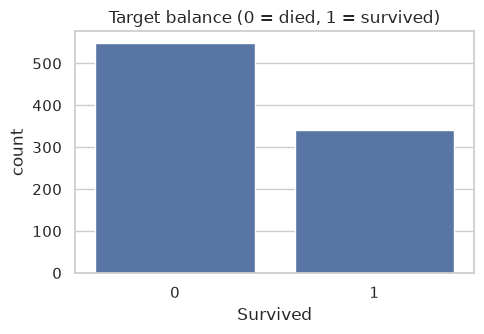

In [7]:
target_counts = train[TARGET].value_counts().sort_index()
target_rates = train[TARGET].value_counts(normalize=True).sort_index()
print(pd.DataFrame({"count": target_counts, "rate": target_rates.round(3)}))

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=train, x=TARGET, ax=ax)
ax.set_title("Target balance (0 = died, 1 = survived)")
plt.tight_layout()
plt.show()

### Survival by Sex, Pclass and Embarked

Each table shows the number of passengers in a group (`count`) and the share who survived (`survival_rate`). Look for groups whose rate is far from the overall rate.

In [8]:
def survival_table(df, column):
    # Count and survival rate per category of `column`.
    table = df.groupby(column, dropna=False)[TARGET].agg(count="size", survival_rate="mean")
    table["survival_rate"] = table["survival_rate"].round(3)
    return table


print("Overall survival rate:", round(train[TARGET].mean(), 3))
for col in ["Sex", "Pclass", "Embarked"]:
    print(f"\n--- Survival by {col} ---")
    print(survival_table(train, col))

Overall survival rate: 0.384

--- Survival by Sex ---
        count  survival_rate
Sex                         
female    314          0.742
male      577          0.189

--- Survival by Pclass ---
        count  survival_rate
Pclass                      
1         216          0.630
2         184          0.473
3         491          0.242

--- Survival by Embarked ---
          count  survival_rate
Embarked                      
C           168          0.554
Q            77          0.390
S           644          0.337
NaN           2          1.000


The bar plots below show the survival rates for groups with known category values. The height of each bar is the share of passengers in that group who survived.

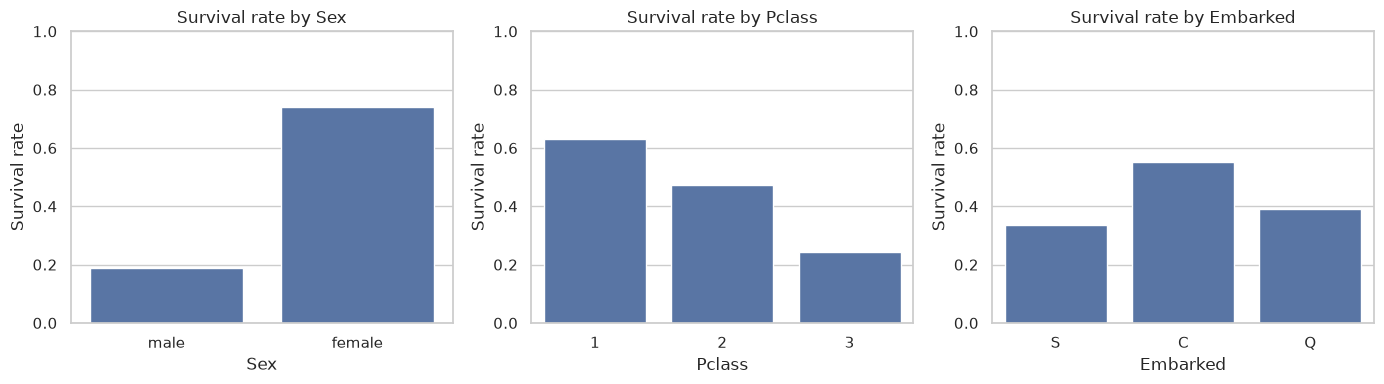

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["Sex", "Pclass", "Embarked"]):
    sns.barplot(data=train, x=col, y=TARGET, errorbar=None, ax=ax)
    ax.set_title(f"Survival rate by {col}")
    ax.set_ylabel("Survival rate")
    ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

### Age and Fare

- **Age:** compare the age distributions for survivors and non-survivors with recorded ages. Each group’s density is scaled separately, so the plot shows which ages are more common within each group. To estimate survival rates by age, divide the survivor count by the total passenger count in each age range.
- **Fare:** fares are very skewed (a few very expensive tickets). We plot them on a log scale so the shape is easier to see. Higher fares usually mean a better class.

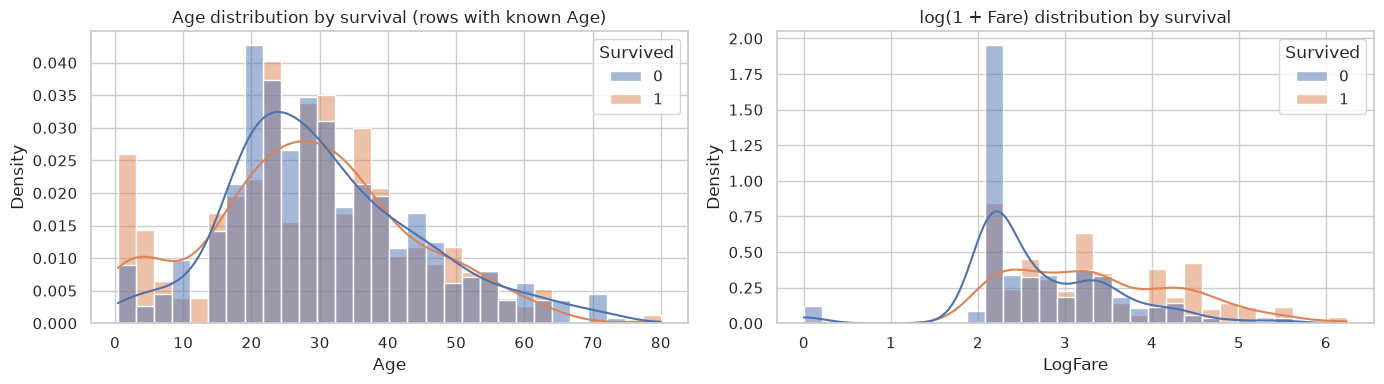

Age and Fare summary (train):
          Age    Fare
count  714.00  891.00
mean    29.70   32.20
std     14.53   49.69
min      0.42    0.00
25%     20.12    7.91
50%     28.00   14.45
75%     38.00   31.00
max     80.00  512.33

Skewness of Fare: 4.79 | skewness of log(1 + Fare): 0.39


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(data=train, x="Age", hue=TARGET, bins=30, kde=True,
             stat="density", common_norm=False, ax=axes[0])
axes[0].set_title("Age distribution by survival (rows with known Age)")

sns.histplot(data=train.assign(LogFare=np.log1p(train["Fare"])), x="LogFare", hue=TARGET,
             bins=30, kde=True, stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("log(1 + Fare) distribution by survival")

plt.tight_layout()
plt.show()

print("Age and Fare summary (train):")
print(train[["Age", "Fare"]].describe().round(2))
print("\nSkewness of Fare:", round(train["Fare"].skew(), 2),
      "| skewness of log(1 + Fare):", round(np.log1p(train["Fare"]).skew(), 2))

### Family on board (SibSp and Parch)

`SibSp` = siblings/spouses on board, `Parch` = parents/children on board. We look at their sum plus one (the passenger) as a quick family-size check. Very small and very large families may behave differently from medium ones.

            count  survival_rate
FamilySize                      
1             537          0.304
2             161          0.553
3             102          0.578
4              29          0.724
5              15          0.200
6              22          0.136
7              12          0.333
8               6          0.000
11              7          0.000


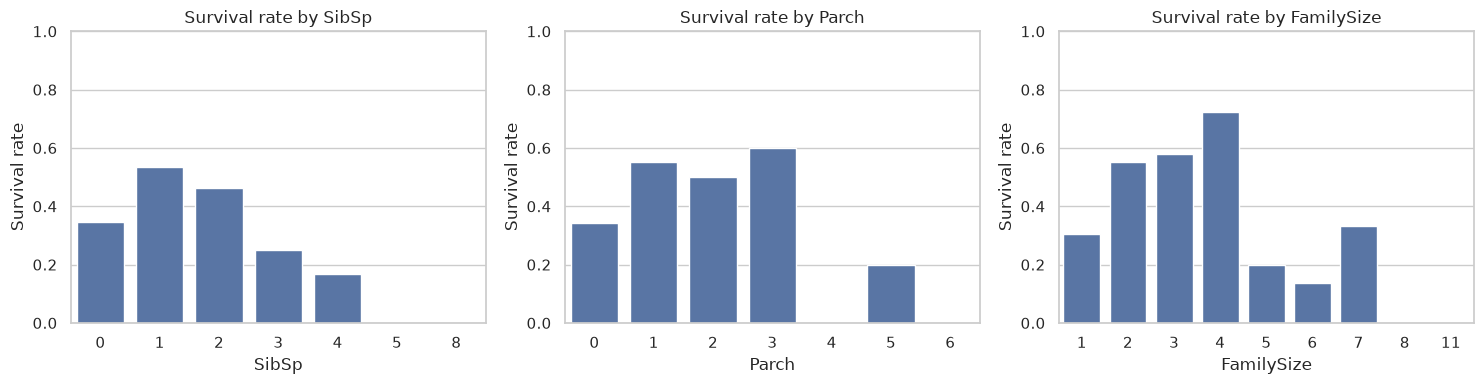

In [11]:
eda_family = train.assign(FamilySize=train["SibSp"] + train["Parch"] + 1)
print(survival_table(eda_family, "FamilySize"))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["SibSp", "Parch", "FamilySize"]):
    sns.barplot(data=eda_family, x=col, y=TARGET, errorbar=None, ax=ax)
    ax.set_title(f"Survival rate by {col}")
    ax.set_ylabel("Survival rate")
    ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

### Cabin missingness

Most `Cabin` values are empty. The share of missing cabin entries varies by passenger class in the training data. So "cabin is missing" can itself be a useful signal. The first letter of the cabin is the **deck**.

Share of missing Cabin (train): 0.771
Share of missing Cabin (test):  0.782

--- Survival by HasCabin ---
          count  survival_rate
HasCabin                      
0           687          0.300
1           204          0.667

--- Cabin missing rate by Pclass ---
Pclass
1    0.185
2    0.913
3    0.976
Name: cabin_missing_rate, dtype: float64

--- Survival by Deck (U = unknown) ---
      count  survival_rate
Deck                      
A        15          0.467
B        47          0.745
C        59          0.593
D        33          0.758
E        32          0.750
F        13          0.615
G         4          0.500
T         1          0.000
U       687          0.300


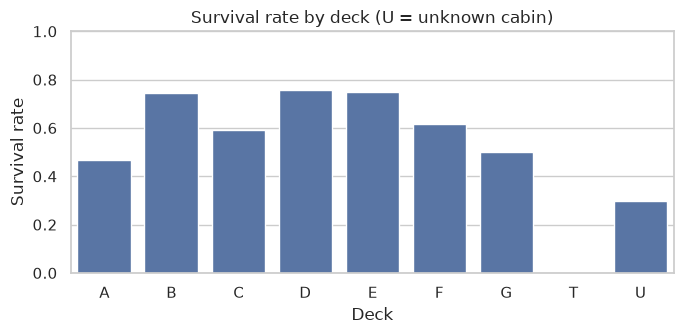

In [12]:
eda_cabin = train.assign(
    HasCabin=train["Cabin"].notna().astype(int),
    Deck=train["Cabin"].str[0].fillna("U"),
)
print("Share of missing Cabin (train):", round(train["Cabin"].isna().mean(), 3))
print("Share of missing Cabin (test): ", round(test["Cabin"].isna().mean(), 3))
print("\n--- Survival by HasCabin ---")
print(survival_table(eda_cabin, "HasCabin"))
print("\n--- Cabin missing rate by Pclass ---")
print(train.groupby("Pclass")["Cabin"].apply(lambda s: s.isna().mean()).round(3).rename("cabin_missing_rate"))
print("\n--- Survival by Deck (U = unknown) ---")
print(survival_table(eda_cabin, "Deck"))

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.barplot(data=eda_cabin, x="Deck", y=TARGET, errorbar=None,
            order=sorted(eda_cabin["Deck"].unique()), ax=ax)
ax.set_title("Survival rate by deck (U = unknown cabin)")
ax.set_ylabel("Survival rate")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

## C. Cleaning

**Golden rule: learn every fill value from the training data only, then apply it to the test data.** If we used test data to compute medians, information would "leak" from the test set into training.

To make this rule automatic, we write the cleaning as a small scikit-learn transformer:

- `fit(train)` learns the fill values from the data it is given.
- `transform(df)` applies those stored values to any table (train or test).

Later, during cross-validation, the same transformer is re-fitted inside each fold, so even the validation folds do not leak.

Our choices:

| Column | Plan |
|---|---|
| `Age` | Median Age of the passenger's **Pclass + Sex** group (learned on train). If a group is unseen, use the overall train median. |
| `Embarked` | Most common port (mode) in train. |
| `Fare` | Median Fare of the passenger's **Pclass** in train (the test file has a missing Fare). |
| `Cabin` | Keep only the **deck letter**; a missing cabin becomes its own deck `"U"` (unknown). We also add `HasCabin`. |
| `Ticket` | Not used (dropped). |
| `PassengerId` | **Not a feature.** We keep it aside only to build the submission file. |

We use Pclass + Sex for Age (rather than Title) so the cleaning step does not depend on the feature-engineering step.

In [13]:
class TitanicCleaner(BaseEstimator, TransformerMixin):
    # Fill missing values using statistics learned in fit() (train only).

    def fit(self, X, y=None):
        df = X
        self.age_medians_ = df.groupby(["Pclass", "Sex"])["Age"].median()
        self.age_global_median_ = float(df["Age"].median())
        self.embarked_mode_ = df["Embarked"].mode().iloc[0]
        self.fare_medians_ = df.groupby("Pclass")["Fare"].median()
        self.fare_global_median_ = float(df["Fare"].median())
        return self

    def transform(self, X):
        df = X.copy()

        # Age: median of the (Pclass, Sex) group, then overall median as a fallback.
        age_lookup = self.age_medians_.to_dict()
        group_age = pd.Series(
            [age_lookup.get(key, np.nan) for key in zip(df["Pclass"], df["Sex"])],
            index=df.index, dtype=float,
        )
        df["Age"] = df["Age"].fillna(group_age).fillna(self.age_global_median_)

        # Embarked: most common port in train.
        df["Embarked"] = df["Embarked"].fillna(self.embarked_mode_)

        # Fare: median of the passenger's class, then overall median as a fallback.
        fare_lookup = self.fare_medians_.to_dict()
        class_fare = pd.Series([fare_lookup.get(p, np.nan) for p in df["Pclass"]],
                               index=df.index, dtype=float)
        df["Fare"] = df["Fare"].fillna(class_fare).fillna(self.fare_global_median_)

        # Cabin: deck letter, with "U" for unknown.
        df["HasCabin"] = df["Cabin"].notna().astype(int)
        df["Deck"] = df["Cabin"].str[0].fillna("U").astype(str)

        # Columns we do not use as features.
        return df.drop(columns=["Cabin", "Ticket"])

Now we fit the cleaner on the training data and look at the fill values it learned. Then we apply it to both files and confirm the missing values are gone (the `Survived` column only exists in train, so its test entry is marked as unavailable).

In [14]:
cleaner = TitanicCleaner().fit(train)

print("Median Age by (Pclass, Sex), learned on train:")
print(cleaner.age_medians_.round(1))
print("\nOverall train Age median (fallback):", cleaner.age_global_median_)
print("Embarked mode (train):", cleaner.embarked_mode_)
print("\nMedian Fare by Pclass, learned on train:")
print(cleaner.fare_medians_.round(2))

train_clean = cleaner.transform(train)
test_clean = cleaner.transform(test)

print("\nMissing values after cleaning:")
print(pd.DataFrame({"train": train_clean.isna().sum(),
                    "test": test_clean.isna().sum().reindex(train_clean.columns).astype("Int64")}))

Median Age by (Pclass, Sex), learned on train:
Pclass  Sex   
1       female    35.0
        male      40.0
2       female    28.0
        male      30.0
3       female    21.5
        male      25.0
Name: Age, dtype: float64

Overall train Age median (fallback): 28.0
Embarked mode (train): S

Median Fare by Pclass, learned on train:
Pclass
1    60.29
2    14.25
3     8.05
Name: Fare, dtype: float64

Missing values after cleaning:
             train  test
PassengerId      0     0
Survived         0  <NA>
Pclass           0     0
Name             0     0
Sex              0     0
Age              0     0
SibSp            0     0
Parch            0     0
Fare             0     0
Embarked         0     0
HasCabin         0     0
Deck             0     0


## D. Feature engineering

New features can make patterns easier for the model to find:

- **Title** from the name (e.g. "Mr", "Mrs", "Miss", "Master"). It mixes information about sex, age and social status. Spelling variants (`Mlle`, `Ms`, `Mme`) are mapped to common titles. Titles that appear fewer than `RARE_TITLE_MIN_COUNT` times **in the training data** are grouped as `"Rare"`. Titles never seen in training also become `"Rare"`.
- **FamilySize** = `SibSp + Parch + 1`, and **IsAlone** = 1 when FamilySize is 1.
- **LogFare** = `log(1 + Fare)`. Fare is very skewed (see the EDA). The log makes it more balanced, which helps linear models such as Logistic Regression. Tree models do not care much either way.

We do **not** bin Age or Fare: the tree models can find useful split points on their own, and binning would throw information away for the linear model.

Like the cleaner, this is a transformer whose `fit()` only looks at the training data (it learns which titles are common).

In [15]:
RARE_TITLE_MIN_COUNT = 10
TITLE_FIXES = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}


def extract_title(names):
    # "Braund, Mr. Owen Harris" -> "Mr"
    return names.str.extract(r",\s*([^\.]+)\.", expand=False).str.strip().replace(TITLE_FIXES)


class TitanicFeatures(BaseEstimator, TransformerMixin):
    # Add Title, FamilySize, IsAlone and LogFare. fit() learns the common titles.

    def __init__(self, rare_title_min_count=RARE_TITLE_MIN_COUNT):
        self.rare_title_min_count = rare_title_min_count

    def fit(self, X, y=None):
        counts = extract_title(X["Name"]).value_counts()
        self.common_titles_ = sorted(counts[counts >= self.rare_title_min_count].index)
        return self

    def transform(self, X):
        df = X.copy()
        title = extract_title(df["Name"])
        df["Title"] = title.where(title.isin(self.common_titles_), "Rare").astype(str)
        df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
        df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
        df["LogFare"] = np.log1p(df["Fare"])
        return df

In [16]:
featurizer = TitanicFeatures().fit(train_clean)
train_feat = featurizer.transform(train_clean)
test_feat = featurizer.transform(test_clean)

print("Common titles learned on train:", featurizer.common_titles_)
print("\nRaw titles in train (before grouping):")
print(extract_title(train["Name"]).value_counts())
print("\n--- Survival by grouped Title (train) ---")
print(survival_table(train_feat, "Title"))
print("\nGrouped titles in test:")
print(test_feat["Title"].value_counts())

Common titles learned on train: ['Master', 'Miss', 'Mr', 'Mrs']

Raw titles in train (before grouping):
Name
Mr              517
Miss            185
Mrs             126
Master           40
Dr                7
Rev               6
Major             2
Col               2
Don               1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

--- Survival by grouped Title (train) ---
        count  survival_rate
Title                       
Master     40          0.575
Miss      185          0.703
Mr        517          0.157
Mrs       126          0.794
Rare       23          0.348

Grouped titles in test:
Title
Mr        240
Miss       79
Mrs        72
Master     21
Rare        6
Name: count, dtype: int64


### Final feature list and encoding

Models need numbers, so we encode the text columns:

- **Numeric** columns are standardised (mean 0, standard deviation 1). This matters for Logistic Regression and is harmless for trees.
- **Binary** columns (0/1) are passed through unchanged.
- **Categorical** columns get **one-hot encoding**: one 0/1 column per category. The encoder is fitted on train only; categories that only appear in test are ignored (all zeros).

`Pclass` is kept as a number because the classes have a natural order (1st > 2nd > 3rd).

In [17]:
NUMERIC_FEATURES = ["Pclass", "Age", "LogFare", "SibSp", "Parch", "FamilySize"]
BINARY_FEATURES = ["IsAlone", "HasCabin"]
CATEGORICAL_FEATURES = ["Sex", "Embarked", "Title", "Deck"]
FEATURES = NUMERIC_FEATURES + BINARY_FEATURES + CATEGORICAL_FEATURES


def make_encoder():
    encoder = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), NUMERIC_FEATURES),
            ("bin", "passthrough", BINARY_FEATURES),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )
    return encoder.set_output(transform="pandas")


encoder = make_encoder().fit(train_feat[FEATURES])
X_train_enc = encoder.transform(train_feat[FEATURES])
X_test_enc = encoder.transform(test_feat[FEATURES])

print("Input features used (before encoding):", FEATURES)
print("\nEncoded feature names:")
print(list(X_train_enc.columns))
print("\nTrain feature matrix shape:", X_train_enc.shape)
print("Test feature matrix shape: ", X_test_enc.shape)

Input features used (before encoding): ['Pclass', 'Age', 'LogFare', 'SibSp', 'Parch', 'FamilySize', 'IsAlone', 'HasCabin', 'Sex', 'Embarked', 'Title', 'Deck']

Encoded feature names:
['Pclass', 'Age', 'LogFare', 'SibSp', 'Parch', 'FamilySize', 'IsAlone', 'HasCabin', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Title_Master', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare', 'Deck_A', 'Deck_B', 'Deck_C', 'Deck_D', 'Deck_E', 'Deck_F', 'Deck_G', 'Deck_T', 'Deck_U']

Train feature matrix shape: (891, 27)
Test feature matrix shape:  (418, 27)


In [18]:
print("Sample of the features before encoding:")
print(train_feat[[ID_COL] + FEATURES].head())
print("\nSample of the encoded matrix (what the model sees):")
X_train_enc.head().round(3)

Sample of the features before encoding:
   PassengerId  Pclass   Age   LogFare  SibSp  Parch  FamilySize  IsAlone  HasCabin     Sex Embarked Title Deck
0            1       3  22.0  2.110213      1      0           2        0         0    male        S    Mr    U
1            2       1  38.0  4.280593      1      0           2        0         1  female        C   Mrs    C
2            3       3  26.0  2.188856      0      0           1        1         0  female        S  Miss    U
3            4       1  35.0  3.990834      1      0           2        0         1  female        S   Mrs    C
4            5       3  35.0  2.202765      0      0           1        1         0    male        S    Mr    U

Sample of the encoded matrix (what the model sees):


,Pclass,Age,LogFare,SibSp,Parch,FamilySize,IsAlone,HasCabin,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T,Deck_U
0,0.827,-0.535,-0.880,0.433,-0.474,0.059,0,0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,-1.566,0.668,1.361,0.433,-0.474,0.059,0,1,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.827,-0.234,-0.799,-0.475,-0.474,-0.561,1,0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,-1.566,0.443,1.062,0.433,-0.474,0.059,0,1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.827,0.443,-0.784,-0.475,-0.474,-0.561,1,0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


### Putting it together in a pipeline

For modelling we chain all steps into one scikit-learn `Pipeline`: **clean → add features → encode → model**.

The model input `X` is the raw training table without `Survived`; `y` is `Survived`. Because every step is inside the pipeline, cross-validation re-learns the medians, common titles and encoder in each fold from that fold's training part only.

In [19]:
X_raw = train.drop(columns=[TARGET])
y = train[TARGET].astype(int)
X_test_raw = test.copy()


def make_pipeline(model, encoder=None):
    return Pipeline([
        ("clean", TitanicCleaner()),
        ("features", TitanicFeatures()),
        ("encode", encoder if encoder is not None else make_encoder()),
        ("model", model),
    ])


print("X_raw shape:", X_raw.shape, "| y shape:", y.shape, "| X_test_raw shape:", X_test_raw.shape)

X_raw shape: (891, 11) | y shape: (891,) | X_test_raw shape: (418, 11)


## E. Model comparison with cross-validation

**Cross-validation (CV)** compares models by scoring them on held-out training rows.

1. Split the training data into K roughly equal parts (folds). The number of folds is `N_SPLITS` in the code.
2. Train on K−1 folds and score on the remaining fold.
3. Repeat so each fold is used for scoring once, then average the scores.

We use `StratifiedKFold`, which keeps the survived/died ratio about the same in each fold, with `shuffle=True` and `random_state=SEED`.

Models we compare:

- **Baseline – most frequent:** always predicts the most common class. Any useful model must beat it.
- **Baseline – Sex + Pclass:** Logistic Regression using only two columns.
- **Logistic Regression:** a simple linear model on all features.
- **Random Forest:** many decision trees averaged together.
- **Gradient Boosting:** trees built one after another, each fixing earlier mistakes.
- **XGBoost:** another gradient-boosting library (only if it is installed).

Model sizes are kept modest so the notebook runs quickly on a CPU.

For each model we report the mean and standard deviation of **accuracy** (share of correct predictions) and **ROC-AUC** (how well the model ranks survivors above non-survivors; 0.5 = random, 1.0 = perfect) over the folds.

In [20]:
N_SPLITS = 5
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

# Encoder for the small baseline: only Sex and Pclass.
sex_pclass_encoder = ColumnTransformer(
    [("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Sex", "Pclass"])],
    remainder="drop",
)

# complexity: lower = simpler (used only to break ties).
candidates = {
    "Baseline: most frequent": dict(
        pipe=make_pipeline(DummyClassifier(strategy="most_frequent", random_state=SEED)),
        complexity=0, baseline=True),
    "Baseline: LogReg (Sex + Pclass)": dict(
        pipe=make_pipeline(LogisticRegression(max_iter=1000, random_state=SEED),
                           encoder=sex_pclass_encoder),
        complexity=1, baseline=True),
    "Logistic Regression": dict(
        pipe=make_pipeline(LogisticRegression(C=1.0, max_iter=1000, random_state=SEED)),
        complexity=2, baseline=False),
    "Random Forest": dict(
        pipe=make_pipeline(RandomForestClassifier(
            n_estimators=200, max_depth=6, min_samples_leaf=2,
            random_state=SEED, n_jobs=1)),
        complexity=3, baseline=False),
    "Gradient Boosting": dict(
        pipe=make_pipeline(GradientBoostingClassifier(
            n_estimators=150, learning_rate=0.05, max_depth=3,
            subsample=0.9, random_state=SEED)),
        complexity=4, baseline=False),
}
if HAS_XGB:
    candidates["XGBoost"] = dict(
        pipe=make_pipeline(XGBClassifier(
            n_estimators=200, learning_rate=0.05, max_depth=3,
            subsample=0.9, colsample_bytree=0.8, eval_metric="logloss",
            random_state=SEED, n_jobs=1)),
        complexity=5, baseline=False)

print("Models to compare:", list(candidates))

Models to compare: ['Baseline: most frequent', 'Baseline: LogReg (Sex + Pclass)', 'Logistic Regression', 'Random Forest', 'Gradient Boosting', 'XGBoost']


In [21]:
rows = []
fold_scores = {}
for name, spec in candidates.items():
    scores = cross_validate(spec["pipe"], X_raw, y, cv=cv,
                            scoring=["accuracy", "roc_auc"], n_jobs=1)
    fold_scores[name] = scores["test_accuracy"]
    rows.append({
        "model": name,
        "baseline": spec["baseline"],
        "complexity": spec["complexity"],
        "cv_acc_mean": scores["test_accuracy"].mean(),
        "cv_acc_std": scores["test_accuracy"].std(),
        "cv_auc_mean": scores["test_roc_auc"].mean(),
        "cv_auc_std": scores["test_roc_auc"].std(),
        "fit_time_s": scores["fit_time"].mean(),
    })

cv_results = pd.DataFrame(rows).set_index("model")
print(f"Cross-validation results ({N_SPLITS} stratified folds, sorted by mean accuracy):")
print(cv_results.sort_values("cv_acc_mean", ascending=False).round(4))

print("\nAccuracy of each fold:")
print(pd.DataFrame(fold_scores, index=[f"fold_{i + 1}" for i in range(N_SPLITS)]).T.round(4))

Cross-validation results (5 stratified folds, sorted by mean accuracy):
                                 baseline  complexity  cv_acc_mean  cv_acc_std  cv_auc_mean  cv_auc_std  fit_time_s
model                                                                                                              
Gradient Boosting                   False           4       0.8473      0.0177       0.8822      0.0165      0.1466
XGBoost                             False           5       0.8440      0.0224       0.8833      0.0178      0.0454
Random Forest                       False           3       0.8339      0.0116       0.8728      0.0223      0.1804
Logistic Regression                 False           2       0.8283      0.0167       0.8743      0.0199      0.0985
Baseline: LogReg (Sex + Pclass)      True           1       0.7868      0.0188       0.8333      0.0258      0.0176
Baseline: most frequent              True           0       0.6162      0.0023       0.5000      0.0000      0.0189


The bar chart shows the mean CV accuracy of each model; the black line on each bar is ± one standard deviation across folds. Compare the real models with the two baselines to see the lift. The lines describe variability across folds. They are not confidence intervals.

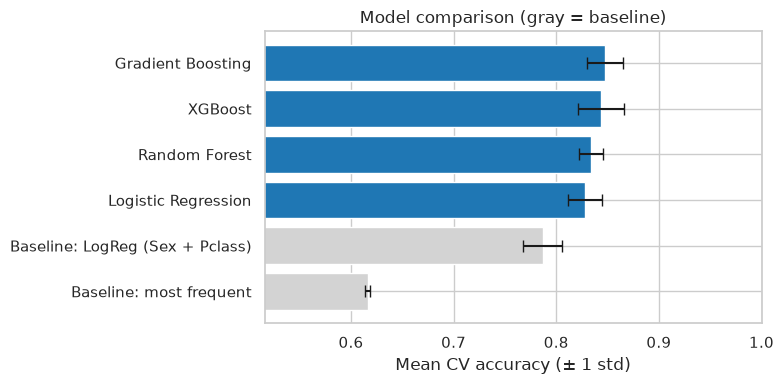

In [22]:
plot_df = cv_results.sort_values("cv_acc_mean")
fig, ax = plt.subplots(figsize=(8, 4))
colors = ["lightgray" if b else "tab:blue" for b in plot_df["baseline"]]
ax.barh(plot_df.index, plot_df["cv_acc_mean"], xerr=plot_df["cv_acc_std"], color=colors, capsize=4)
ax.set_xlabel("Mean CV accuracy (± 1 std)")
ax.set_title("Model comparison (gray = baseline)")
ax.set_xlim(max(0.0, plot_df["cv_acc_mean"].min() - 0.1), 1.0)
plt.tight_layout()
plt.show()

### Picking the winner

The selection rule is written in code so it is applied the same way every time:

1. Only real models are eligible (baselines are just for comparison).
2. Highest **mean CV accuracy** wins (compared after rounding to 4 decimals).
3. Ties are broken by higher **mean CV ROC-AUC**, then by the **simpler** model.

In [23]:
eligible = cv_results[~cv_results["baseline"]].copy()
eligible["acc_rounded"] = eligible["cv_acc_mean"].round(4)
ranking = eligible.sort_values(["acc_rounded", "cv_auc_mean", "complexity"],
                               ascending=[False, False, True])

best_name = ranking.index[0]
best_row = cv_results.loc[best_name]
majority_acc = cv_results.loc["Baseline: most frequent", "cv_acc_mean"]

print("Ranking of eligible models:")
print(ranking[["cv_acc_mean", "cv_acc_std", "cv_auc_mean", "complexity"]].round(4))
print(f"\nWinner: {best_name}")
print(f"  mean CV accuracy = {best_row['cv_acc_mean']:.4f} (std {best_row['cv_acc_std']:.4f})")
print(f"  mean CV ROC-AUC  = {best_row['cv_auc_mean']:.4f} (std {best_row['cv_auc_std']:.4f})")
print(f"  lift over most-frequent baseline = {best_row['cv_acc_mean'] - majority_acc:+.4f} accuracy")

Ranking of eligible models:
                     cv_acc_mean  cv_acc_std  cv_auc_mean  complexity
model                                                                
Gradient Boosting         0.8473      0.0177       0.8822           4
XGBoost                   0.8440      0.0224       0.8833           5
Random Forest             0.8339      0.0116       0.8728           3
Logistic Regression       0.8283      0.0167       0.8743           2

Winner: Gradient Boosting
  mean CV accuracy = 0.8473 (std 0.0177)
  mean CV ROC-AUC  = 0.8822 (std 0.0165)
  lift over most-frequent baseline = +0.2312 accuracy


## F. Final model

We now refit the winning pipeline on **all** training rows.

- **Training accuracy** is measured on the same rows the model learned from, so it is optimistic. It is printed only to check for heavy overfitting (a big gap to the CV accuracy).
- The **CV accuracy** from section E comes from held-out folds. Because we used those same scores to select the winner, its reported score can be optimistic.
- We cannot compute a test accuracy here: the true test labels are hidden by Kaggle.

In [24]:
final_model = clone(candidates[best_name]["pipe"])
final_model.fit(X_raw, y)

train_acc = accuracy_score(y, final_model.predict(X_raw))
print("Final model:", best_name)
print(f"Training accuracy (optimistic):   {train_acc:.4f}")
print(f"Mean CV accuracy (from section E): {best_row['cv_acc_mean']:.4f} ± {best_row['cv_acc_std']:.4f}")
print(f"Gap (train - CV):                  {train_acc - best_row['cv_acc_mean']:+.4f}")

Final model: Gradient Boosting
Training accuracy (optimistic):   0.8979
Mean CV accuracy (from section E): 0.8473 ± 0.0177
Gap (train - CV):                  +0.0505


### What the final model relies on

For tree models we show the built-in feature importances; for Logistic Regression we show absolute coefficient sizes. The bars summarize the fitted model. Their magnitudes depend on feature scaling and correlations, and they do not establish what caused survival.

Title_Mr        0.3305
LogFare         0.1516
Pclass          0.1017
Age             0.0913
FamilySize      0.0759
Sex_male        0.0750
Sex_female      0.0559
Title_Rare      0.0304
HasCabin        0.0196
Title_Master    0.0158
Deck_E          0.0105
Embarked_S      0.0090
Deck_U          0.0073
SibSp           0.0040
Deck_D          0.0034
dtype: float64


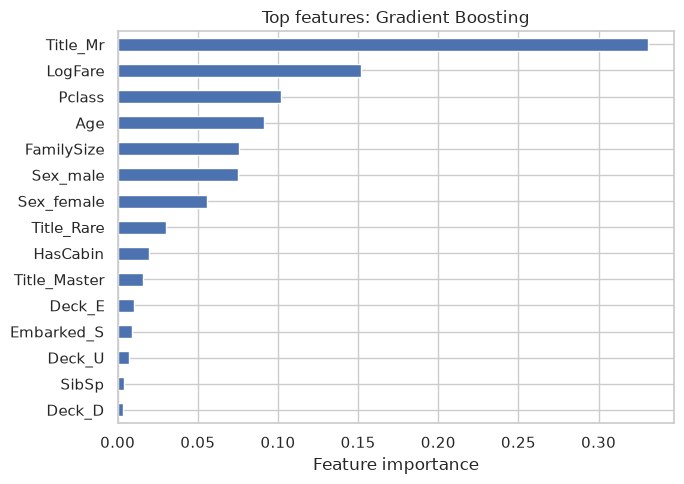

In [25]:
fitted_est = final_model.named_steps["model"]
feature_names = final_model.named_steps["encode"].get_feature_names_out()

if hasattr(fitted_est, "feature_importances_"):
    importance = pd.Series(fitted_est.feature_importances_, index=feature_names)
    label = "Feature importance"
elif hasattr(fitted_est, "coef_"):
    importance = pd.Series(np.abs(fitted_est.coef_[0]), index=feature_names)
    label = "|coefficient|"
else:
    importance = None

if importance is not None:
    top = importance.sort_values(ascending=False).head(15)
    print(top.round(4))
    fig, ax = plt.subplots(figsize=(7, 5))
    top.sort_values().plot.barh(ax=ax)
    ax.set_xlabel(label)
    ax.set_title(f"Top features: {best_name}")
    plt.tight_layout()
    plt.show()

### Predict the test set and write `submission.csv`

The submission file needs exactly two columns: `PassengerId` and `Survived` (0 or 1), with one row per test passenger. We run a few checks before saving.

In [26]:
test_pred = final_model.predict(X_test_raw).astype(int)

pred_counts = pd.Series(test_pred).value_counts().sort_index()
print("Predicted Survived counts on test:")
print(pred_counts.rename_axis("Survived").to_frame("count"))
print(f"Predicted survival rate on test: {test_pred.mean():.3f}")
print(f"Survival rate in train (for reference): {y.mean():.3f}")

submission = pd.DataFrame({ID_COL: test[ID_COL].astype(int), "Survived": test_pred})

# Sanity checks: one row per test passenger, unique ids, labels in {0, 1}.
assert len(submission) == len(test)
assert submission[ID_COL].is_unique
assert set(submission[ID_COL]) == set(test[ID_COL])
assert set(submission["Survived"].unique()) <= {0, 1}
print("Submission checks passed.")

Predicted Survived counts on test:
          count
Survived       
0           266
1           152
Predicted survival rate on test: 0.364
Survival rate in train (for reference): 0.384
Submission checks passed.


In [27]:
output_paths = [Path.cwd() / "submission.csv"]
project_dir = Path("/workspace/kaggle/titanic")
if project_dir.is_dir() and (project_dir / "submission.csv").resolve() != output_paths[0].resolve():
    output_paths.append(project_dir / "submission.csv")

for path in output_paths:
    submission.to_csv(path, index=False)
    written = pd.read_csv(path)
    print(f"Wrote {path.resolve()}  ->  {len(written)} rows, columns {list(written.columns)}")

print("\nFirst rows of the written file:")
pd.read_csv(output_paths[0]).head()

Wrote /workspace/kaggle/titanic/submission.csv  ->  418 rows, columns ['PassengerId', 'Survived']

First rows of the written file:


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


`submission.csv` is the file you upload on the Kaggle competition page (*Submit Prediction*). Kaggle computes the public leaderboard score after you submit. The local CV score and the leaderboard score are measured on different passengers and may differ.

## G. (Optional) Error analysis

To see *which* mistakes the model makes, we use **out-of-fold (OOF) predictions**: each training passenger is predicted by a model that did not see them during training (same folds as in section E). This is only for understanding; the final model above still uses all training rows.

- The **confusion matrix** counts correct and wrong predictions for each true class.
- The **classification report** shows precision (how many predicted survivors really survived), recall (how many real survivors we found) and F1 (a balance of both) per class.

OOF accuracy (Gradient Boosting): 0.8474

Classification report (out-of-fold):
              precision    recall  f1-score   support

    Died (0)      0.857     0.903     0.879       549
Survived (1)      0.830     0.757     0.792       342

    accuracy                          0.847       891
   macro avg      0.843     0.830     0.836       891
weighted avg      0.846     0.847     0.846       891



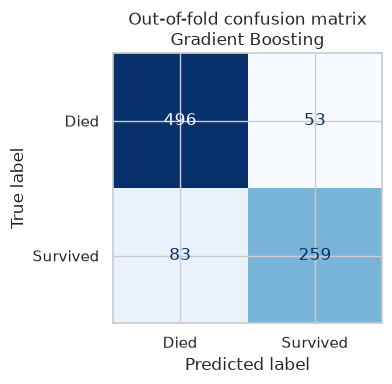

In [28]:
oof_pred = cross_val_predict(clone(candidates[best_name]["pipe"]), X_raw, y, cv=cv, n_jobs=1)

print(f"OOF accuracy ({best_name}): {accuracy_score(y, oof_pred):.4f}")
print("\nClassification report (out-of-fold):")
print(classification_report(y, oof_pred, target_names=["Died (0)", "Survived (1)"], digits=3))

cm = confusion_matrix(y, oof_pred)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm, display_labels=["Died", "Survived"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Out-of-fold confusion matrix\n{best_name}")
plt.tight_layout()
plt.show()

Finally, we check where the errors happen. The table shows the OOF accuracy for each Sex and Pclass group. Lower accuracy means more errors relative to the group’s size. Check the passenger count alongside each accuracy.

In [29]:
errors = train[["Sex", "Pclass"]].assign(correct=(oof_pred == y).astype(int))
error_table = errors.groupby(["Sex", "Pclass"])["correct"].agg(count="size", oof_accuracy="mean")
print(error_table.round(3))

               count  oof_accuracy
Sex    Pclass                     
female 1          94         0.968
       2          76         0.921
       3         144         0.708
male   1         122         0.672
       2         108         0.917
       3         347         0.896


## Summary

- We loaded the data from the first folder that contains `train.csv` and `test.csv`.
- EDA showed which columns relate to survival and which have missing values.
- Cleaning and feature engineering are learned on training data only and live inside a pipeline, so cross-validation is leak-free.
- We compared several models with stratified cross-validation and picked the winner with a rule written in code (see the printed winner in section E).
- The final model was refitted on all training rows and its predictions were saved to `submission.csv`.

Ideas to try next: tune model settings with a small grid search, use ticket-group or surname features, or combine several models (ensembling).